<h1 style="font-size: 32px; background-color:#aa0033; color:#ffffff; padding:8px 16px; border-radius:4px">CSE 351 Course Project: Covid-19 in Germany Analysis</h1>

# Exploratory Data Analysis (EDA)

**Objective:** Get familiar with the dataset, identify useful features and observations, and use visualizations to explore trends and patterns.
## 1. Data Cleaning and Preparation
- Clean the dataset and remove outliers before merging or conducting analysis.
- Identify and explain the cleaning methods and decisions made.
- Address missing values, duplicates, and invalid observations where appropriate.

## 2. COVID-19 Case Trends
- Analyze the overall COVID-19 case trend in Germany.
- Compare case trends across individual states and counties.
- Identify the state and county with the highest and lowest case increasing rates.

## 3. COVID-19 Death Rate Trends
- Analyze the overall COVID-19 death rate trend in Germany.
- Compare death rate trends across individual states and counties.
- Identify the state and county with the highest and lowest death rate increasing rates.

## 4. Demographic Analysis
- **Age and Gender:** Which age/gender group has the highest number of COVID-19 positive cases?
- **Age and Gender:** Which age/gender group has the highest number of COVID-19 deaths?

## 5. Visualizations and Findings
- Use appropriate visualizations to support each analysis.
- Highlight significant trends, differences, and patterns.
- Summarize key findings and explain relevant observations.

---

## 1. Data Cleaning and Preparation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_covid = pd.read_csv("covid_germany/covid_de.csv")
df_demo = pd.read_csv("covid_germany/demographics_de.csv")

print(df_covid.columns)
print(df_demo.columns)
print(df_covid.columns.tolist())
type(df_covid)

Index(['state', 'county', 'age_group', 'gender', 'date', 'cases', 'deaths',
       'recovered'],
      dtype='str')
Index(['state', 'gender', 'age_group', 'population'], dtype='str')
['state', 'county', 'age_group', 'gender', 'date', 'cases', 'deaths', 'recovered']


pandas.DataFrame

In [2]:
'''showing the unclean parts'''
# impossible values
df_unclean = df_covid[
    (df_covid['cases'] <= 0)
    | (df_covid['deaths'] < 0)
    | (df_covid['recovered'] < 0)
    | (df_covid['deaths'] > df_covid['cases'])
    | (df_covid['recovered'] > df_covid['cases'])
    | (df_covid['deaths'] + df_covid['recovered'] > df_covid['cases'])
]
print("Rows with impossible values:", len(df_unclean))
print(df_unclean.head(10))

# trailing whitespace in county names
print("\nCounty names with trailing whitespace:", (df_covid['county'] != df_covid['county'].str.strip()).sum())

# missing values
print("\nMissing values:")
print(df_covid.isna().sum())

# date is stored as text
print("\nDate type:", df_covid['date'].dtype)

# gender labels don't match between the two files
print("\nGender in covid_de:", df_covid['gender'].unique())
print("Gender in demographics_de:", df_demo['gender'].unique())


Rows with impossible values: 82
                    state                    county age_group gender  \
796    Baden-Wuerttemberg        LK Alb-Donau-Kreis     15-34      M   
5583   Baden-Wuerttemberg             LK Boeblingen     60-79      F   
11507  Baden-Wuerttemberg                   LK Calw     80-99      F   
15890  Baden-Wuerttemberg              LK Esslingen     05-14      M   
37629  Baden-Wuerttemberg      LK Main-Tauber-Kreis     80-99      F   
37765  Baden-Wuerttemberg  LK Neckar-Odenwald-Kreis     00-04      M   
39146  Baden-Wuerttemberg  LK Neckar-Odenwald-Kreis     80-99      F   
43744  Baden-Wuerttemberg            LK Ostalbkreis     60-79      M   
50723  Baden-Wuerttemberg             LK Reutlingen     05-14      F   
52766  Baden-Wuerttemberg     LK Rhein-Neckar-Kreis     00-04      F   

             date  cases  deaths  recovered  
796    2021-04-05      0       0          0  
5583   2021-04-02      0       0          0  
11507  2021-04-06      1       0     

In [3]:
'''cleaning df_covid'''
df_clean = df_covid.copy()

# remove trailing whitespace
df_clean['county'] = df_clean['county'].str.strip()

# fix impossible values
df_clean = df_clean.drop(
    df_clean[
        (df_clean['cases'] <= 0)
        | (df_clean['deaths'] < 0)
        | (df_clean['recovered'] < 0)
        | (df_clean['deaths'] > df_clean['cases'])
        | (df_clean['recovered'] > df_clean['cases'])
        | (df_clean['deaths'] + df_clean['recovered'] > df_clean['cases'])
    ].index
).copy()

# fill in missing values
df_clean['gender'] = df_clean['gender'].fillna('Unknown')
df_clean['age_group'] = df_clean['age_group'].fillna('Unknown')

# change date to proper format
df_clean['date'] = pd.to_datetime(df_clean['date'])
df_clean['month'] = df_clean['date'].dt.to_period('M').astype(str)

print("Rows before:", len(df_covid), " after:", len(df_clean))
print("Cases before:", df_covid['cases'].sum(), " after:", df_clean['cases'].sum())
print("Deaths before:", df_covid['deaths'].sum(), " after:", df_clean['deaths'].sum())

Rows before: 691226  after: 691144
Cases before: 2910180  after: 2910085
Deaths before: 77400  after: 77373


In [4]:
'''cleaning df_demo'''
df_demo_clean = df_demo.copy()
df_demo_clean['gender'] = df_demo_clean['gender'].replace({'female': 'F', 'male': 'M'})

In [5]:
# shared by the cases and deaths sections
df_state_pop = df_demo_clean.groupby('state')['population'].sum().to_frame()
total_days = (df_clean['date'].max() - df_clean['date'].min()).days + 1

### Explanation

The raw data had 82 impossible rows (for example 0 cases or recovered = -1), 3166 county names with trailing spaces, missing age_group (2244) and gender (13916), dates stored as text, and gender labels that did not match between the two files (F/M vs female/male). We stripped the county names, dropped the 82 impossible rows, filled missing age_group and gender with 'Unknown', converted date to datetime, and recoded the demographics gender to F/M. This left 691144 of 691226 rows, 2910085 of 2910180 cases and 77373 of 77400 deaths, so almost nothing was lost. We did not remove outliers because the largest single rows (for example the LK Guetersloh outbreak) are real outbreaks, not data errors.

## 2. COVID-19 Case Trends

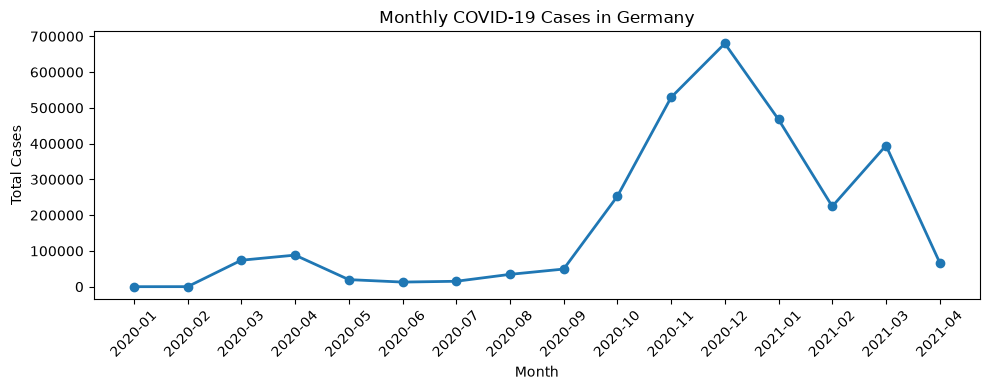

In [6]:
df_monthly_cases = df_clean.groupby('month')['cases'].sum().to_frame()

plt.figure(figsize=(10, 4))
plt.plot(df_monthly_cases.index, df_monthly_cases['cases'], marker='o', linewidth=2)
plt.title('Monthly COVID-19 Cases in Germany')
plt.xlabel('Month')
plt.ylabel('Total Cases')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

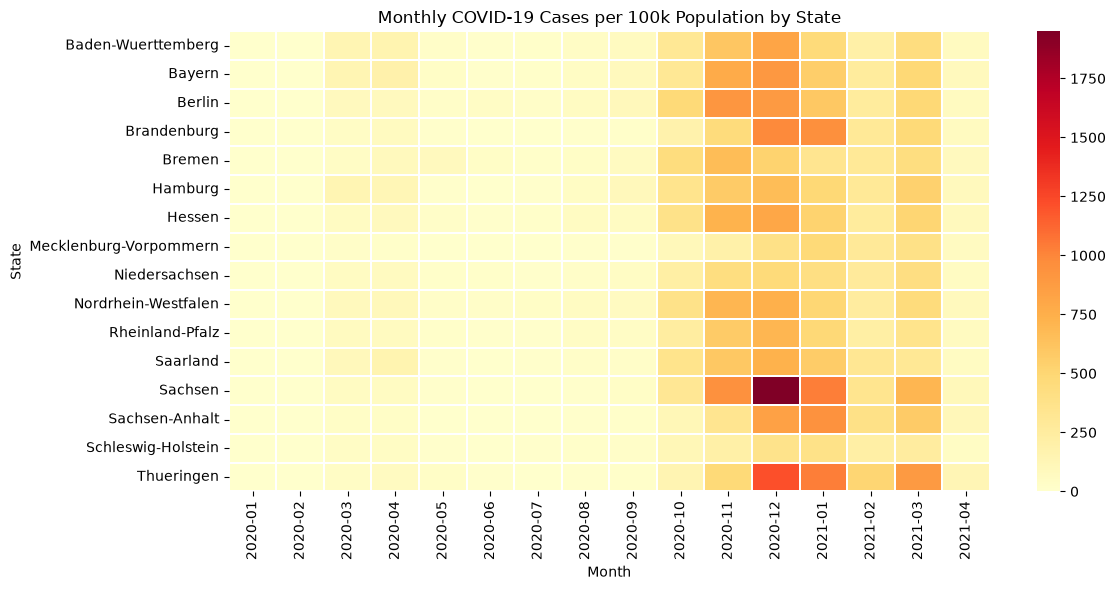

In [24]:
df_state_month_cases = (
    df_clean.groupby(['state', 'month'])['cases']
    .sum()
    .unstack(fill_value=0)
)
df_state_month_cases_100k = df_state_month_cases.div(df_state_pop['population'], axis=0) * 1e5

plt.figure(figsize=(12, 6))
sns.heatmap(df_state_month_cases_100k, linewidths=0.3, cmap='YlOrRd')
plt.title('Monthly COVID-19 Cases per 100k Population by State')
plt.xlabel('Month')
plt.ylabel('State')
plt.tight_layout()
plt.show()

                        total_cases  population  cases_per_day  \
state                                                            
Schleswig-Holstein            51432     2896712     112.789474   
Mecklenburg-Vorpommern        31889     1609675      69.932018   
Niedersachsen                203807     7982448     446.945175   
Rheinland-Pfalz              120116     4084844     263.412281   
Bremen                        21548      682986      47.254386   
Saarland                      32499      990509      71.269737   
Baden-Wuerttemberg           373927    11069533     820.015351   
Sachsen-Anhalt                75856     2208321     166.350877   
Hamburg                       63508     1841179     139.271930   
Nordrhein-Westfalen          629747    17932651    1381.024123   
Brandenburg                   90428     2511917     198.307018   
Hessen                       225993     6265809     495.598684   
Bayern                       513402    13076721    1125.881579   
Berlin    

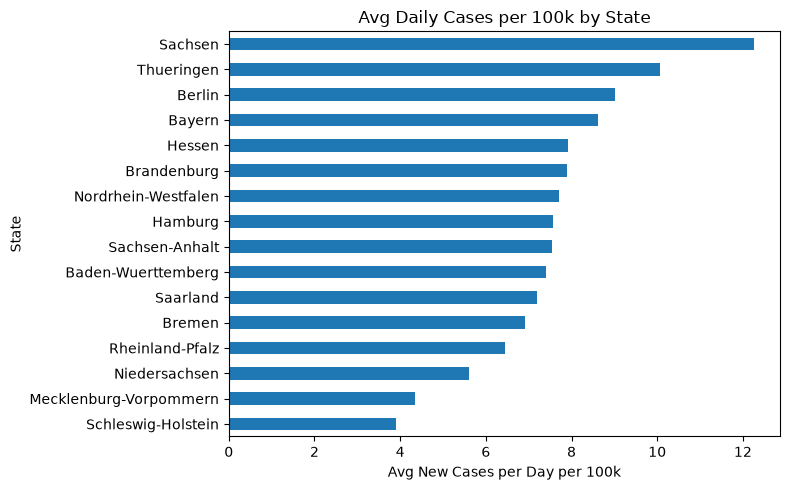

In [8]:
# State increasing rates (raw and per 100k)
df_state_cases = df_clean.groupby('state')['cases'].sum().to_frame('total_cases').join(df_state_pop)
df_state_cases['cases_per_day'] = df_state_cases['total_cases'] / total_days
df_state_cases['cases_per_day_100k'] = df_state_cases['cases_per_day'] / df_state_cases['population'] * 1e5
df_state_cases = df_state_cases.sort_values('cases_per_day_100k')
print(df_state_cases)

plt.figure(figsize=(8, 5))
df_state_cases['cases_per_day_100k'].plot(kind='barh')
plt.title('Avg Daily Cases per 100k by State')
plt.xlabel('Avg New Cases per Day per 100k')
plt.ylabel('State')
plt.tight_layout()
plt.show()

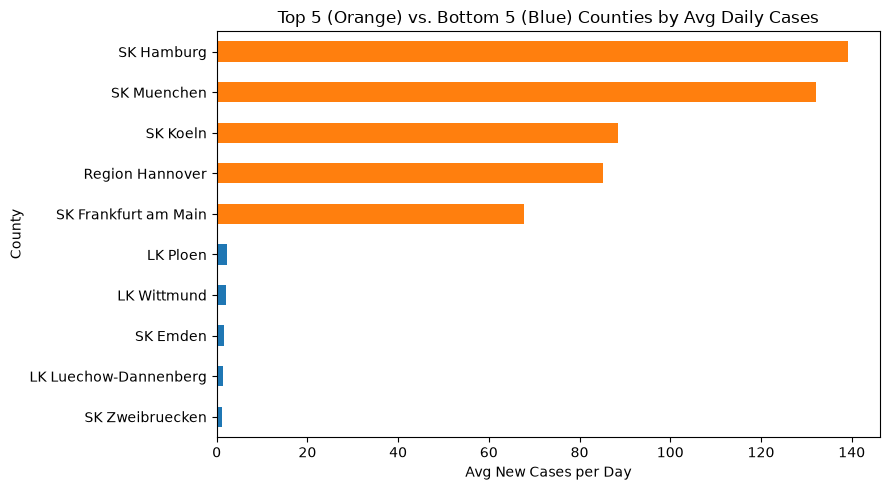

In [9]:
# County increasing rates: Top 5 + Bottom 5 in 1 bar chart
df_county_cases = (df_clean.groupby('county')['cases'].sum() / total_days).sort_values().to_frame('cases_per_day')
df_county_cases_top_bottom = pd.concat([df_county_cases.head(5), df_county_cases.tail(5)])

plt.figure(figsize=(9, 5))
df_county_cases_top_bottom['cases_per_day'].plot(kind='barh', color=['C0'] * 5 + ['C1'] * 5)
plt.title('Top 5 (Orange) vs. Bottom 5 (Blue) Counties by Avg Daily Cases')
plt.xlabel('Avg New Cases per Day')
plt.ylabel('County')
plt.tight_layout()
plt.show()

### Explanation

Germany had a small first wave in spring 2020 and a much bigger second wave that peaked in December 2020; cases rose again in March 2021, and April 2021 is an incomplete month. In the heatmap Sachsen is the darkest state, with its highest values in December 2020. For average new cases per day per 100k, Sachsen is highest (12.252928) and Schleswig-Holstein is lowest (3.893707). By county, the big cities SK Hamburg, SK Muenchen and SK Koeln are highest and SK Zweibruecken is lowest, but counties are not adjusted for population, so big cities rank first.

## 3. COVID-19 Death Rate Trends

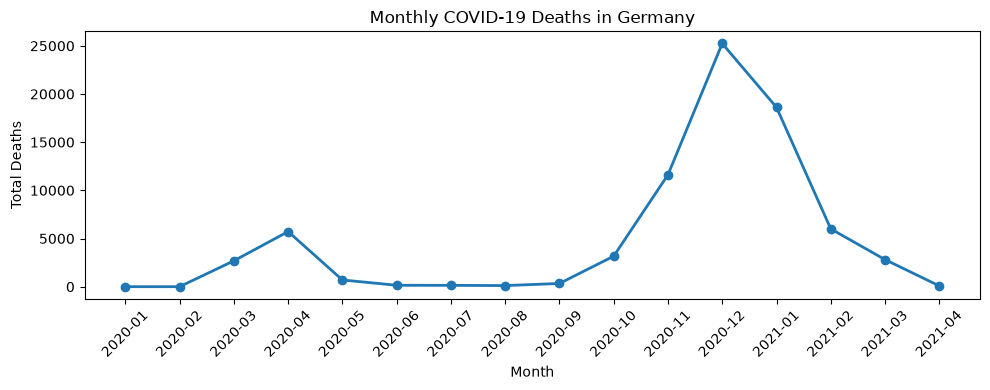

In [10]:
df_monthly_deaths = df_clean.groupby('month')['deaths'].sum().to_frame()

plt.figure(figsize=(10, 4))
plt.plot(df_monthly_deaths.index, df_monthly_deaths['deaths'], marker='o', linewidth=2)
plt.title('Monthly COVID-19 Deaths in Germany')
plt.xlabel('Month')
plt.ylabel('Total Deaths')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

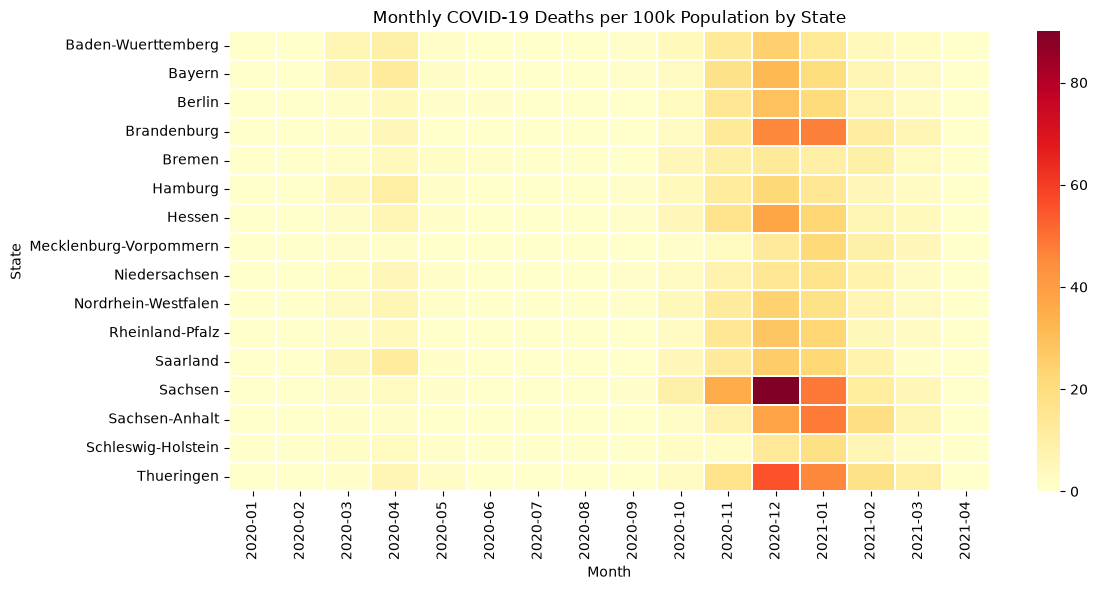

In [23]:
df_state_month_deaths = (
    df_clean.groupby(['state', 'month'])['deaths']
    .sum()
    .unstack(fill_value=0)
)
df_state_month_deaths_100k = df_state_month_deaths.div(df_state_pop['population'], axis=0) * 1e5

plt.figure(figsize=(12, 6))
sns.heatmap(df_state_month_deaths_100k, linewidths=0.3, cmap='YlOrRd')
plt.title('Monthly COVID-19 Deaths per 100k Population by State')
plt.xlabel('Month')
plt.ylabel('State')
plt.tight_layout()
plt.show()

                        total_deaths  population  deaths_per_day  \
state                                                              
Schleswig-Holstein              1446     2896712        3.171053   
Mecklenburg-Vorpommern           881     1609675        1.932018   
Bremen                           411      682986        0.901316   
Niedersachsen                   4936     7982448       10.824561   
Hamburg                         1398     1841179        3.065789   
Baden-Wuerttemberg              8795    11069533       19.287281   
Nordrhein-Westfalen            14400    17932651       31.578947   
Rheinland-Pfalz                 3353     4084844        7.353070   
Berlin                          3089     3644826        6.774123   
Saarland                         929      990509        2.037281   
Hessen                          6405     6265809       14.046053   
Bayern                         13378    13076721       29.337719   
Sachsen-Anhalt                  2752     2208321

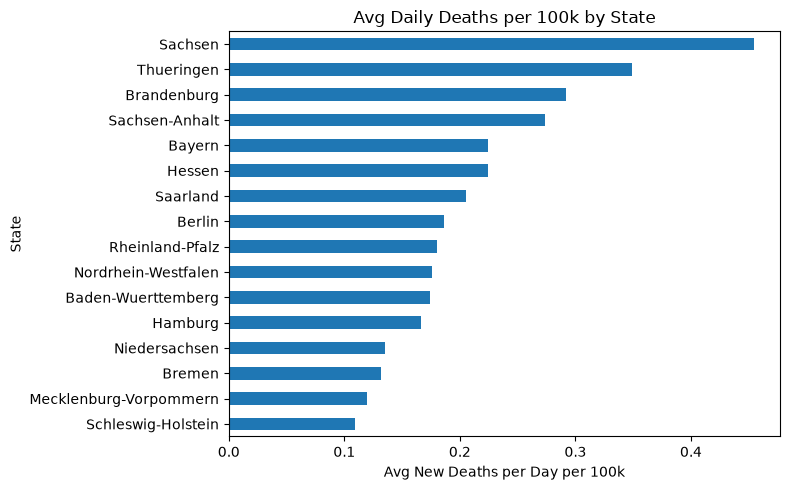

In [12]:
# State increasing rates (raw and per 100k)
df_state_deaths = df_clean.groupby('state')['deaths'].sum().to_frame('total_deaths').join(df_state_pop)
df_state_deaths['deaths_per_day'] = df_state_deaths['total_deaths'] / total_days
df_state_deaths['deaths_per_day_100k'] = df_state_deaths['deaths_per_day'] / df_state_deaths['population'] * 1e5
df_state_deaths = df_state_deaths.sort_values('deaths_per_day_100k')
print(df_state_deaths)

plt.figure(figsize=(8, 5))
df_state_deaths['deaths_per_day_100k'].plot(kind='barh')
plt.title('Avg Daily Deaths per 100k by State')
plt.xlabel('Avg New Deaths per Day per 100k')
plt.ylabel('State')
plt.tight_layout()
plt.show()

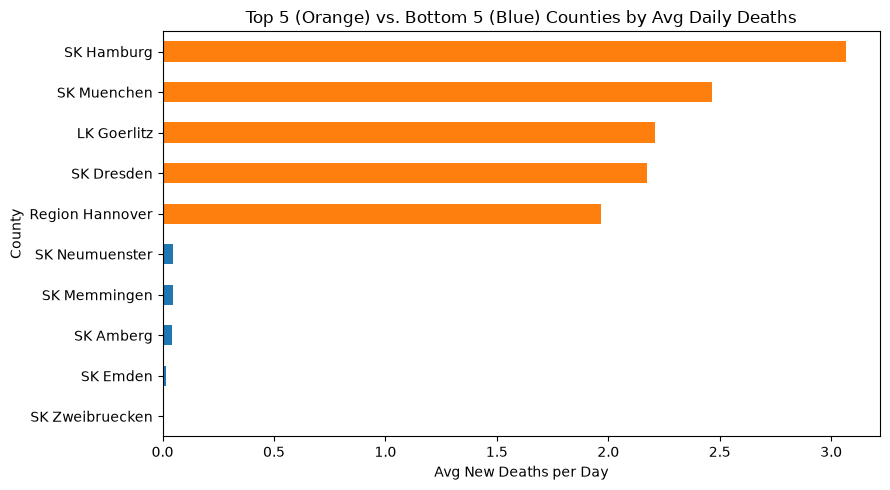

In [13]:
# County increasing rates: Top 5 + Bottom 5 in 1 bar chart
df_county_deaths = (df_clean.groupby('county')['deaths'].sum() / total_days).sort_values().to_frame('deaths_per_day')
df_county_deaths_top_bottom = pd.concat([df_county_deaths.head(5), df_county_deaths.tail(5)])

plt.figure(figsize=(9, 5))
df_county_deaths_top_bottom['deaths_per_day'].plot(kind='barh', color=['C0'] * 5 + ['C1'] * 5)
plt.title('Top 5 (Orange) vs. Bottom 5 (Blue) Counties by Avg Daily Deaths')
plt.xlabel('Avg New Deaths per Day')
plt.ylabel('County')
plt.tight_layout()
plt.show()

### Explanation

Deaths follow the same two waves as cases: a first peak in April 2020 and a bigger peak in December 2020. Deaths were already much lower in March 2021 even though cases rose again that month. In the heatmap Sachsen is again the darkest state, with its highest values in December 2020. For average new deaths per day per 100k, Sachsen is highest (0.454360) and Schleswig-Holstein is lowest (0.109471). By county, SK Hamburg, SK Muenchen and LK Goerlitz are highest and SK Zweibruecken is lowest, but counties are not adjusted for population.

## 4. Demographic Analysis (Age and Gender)

Female cases:
            cases
age_group        
00-04       30555
05-14       85334
15-34      419644
35-59      576105
60-79      221138
80-99      176111
Unknown      1044

Male cases:
            cases
age_group        
00-04       33061
05-14       93740
15-34      416833
35-59      527650
60-79      218653
80-99       88832
Unknown      1088

Highest female cases: 35-59 576105
Highest male cases: 35-59 527650


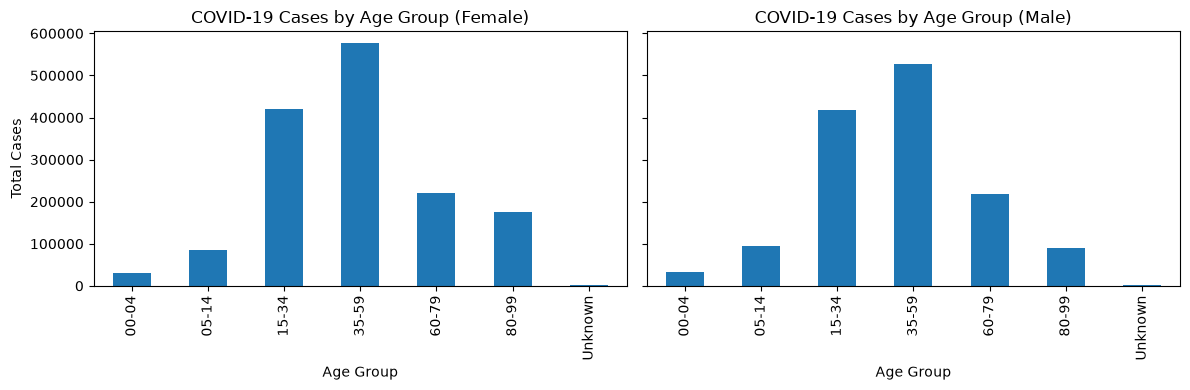

In [14]:
df_cases_female = df_clean[df_clean['gender'] == 'F'].groupby('age_group')['cases'].sum().to_frame()
df_cases_male = df_clean[df_clean['gender'] == 'M'].groupby('age_group')['cases'].sum().to_frame()

print("Female cases:")
print(df_cases_female)
print("\nMale cases:")
print(df_cases_male)

print("\nHighest female cases:", df_cases_female['cases'].idxmax(), df_cases_female['cases'].max())
print("Highest male cases:", df_cases_male['cases'].idxmax(), df_cases_male['cases'].max())

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
df_cases_female['cases'].plot(kind='bar', ax=axes[0])
axes[0].set_title('COVID-19 Cases by Age Group (Female)')
axes[0].set_xlabel('Age Group')
axes[0].set_ylabel('Total Cases')
df_cases_male['cases'].plot(kind='bar', ax=axes[1])
axes[1].set_title('COVID-19 Cases by Age Group (Male)')
axes[1].set_xlabel('Age Group')
plt.tight_layout()
plt.show()


### Explanation

The age/gender group with the most positive cases is women aged 35-59 (576105 cases), followed by men aged 35-59 (527650) and women aged 15-34 (419644). Cases are lowest for children aged 0-4 (30555 girls and 33061 boys). These are total counts, not adjusted for how many people are in each group.

Female deaths:
           deaths
age_group        
00-04           5
05-14           4
15-34          44
35-59         807
60-79        7257
80-99       29225
Unknown         7

Male deaths:
           deaths
age_group        
00-04           3
05-14           3
15-34          69
35-59        1845
60-79       13920
80-99       23977
Unknown         6

Highest female deaths: 80-99 29225
Highest male deaths: 80-99 23977


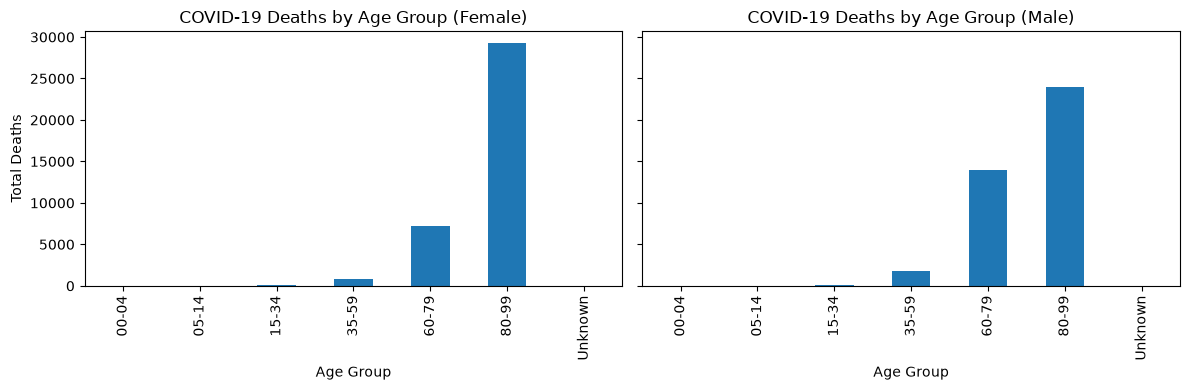

In [15]:
df_deaths_female = df_clean[df_clean['gender'] == 'F'].groupby('age_group')['deaths'].sum().to_frame()
df_deaths_male = df_clean[df_clean['gender'] == 'M'].groupby('age_group')['deaths'].sum().to_frame()

print("Female deaths:")
print(df_deaths_female)
print("\nMale deaths:")
print(df_deaths_male)

print("\nHighest female deaths:", df_deaths_female['deaths'].idxmax(), df_deaths_female['deaths'].max())
print("Highest male deaths:", df_deaths_male['deaths'].idxmax(), df_deaths_male['deaths'].max())

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
df_deaths_female['deaths'].plot(kind='bar', ax=axes[0])
axes[0].set_title('COVID-19 Deaths by Age Group (Female)')
axes[0].set_xlabel('Age Group')
axes[0].set_ylabel('Total Deaths')
df_deaths_male['deaths'].plot(kind='bar', ax=axes[1])
axes[1].set_title('COVID-19 Deaths by Age Group (Male)')
axes[1].set_xlabel('Age Group')
plt.tight_layout()
plt.show()


### Explanation

The group with the most deaths is women aged 80-99 (29225 deaths), followed by men aged 80-99 (23977) and men aged 60-79 (13920). Deaths are very rare below age 35, with at most 5 deaths in any group under 15. Men have more deaths than women in the 35-59 (1845 vs 807) and 60-79 (13920 vs 7257) groups, while women lead in 80-99, where they also have many more cases (176111 vs 88832).

## 5. What Contributes to the Spread of Covid-19?

mobility_grocery_and_pharmacy    -0.592941
relative_humidity                -0.515196
average_temperature_celsius      -0.358368
mobility_retail_and_recreation   -0.354775
mobility_transit_stations        -0.155064
mobility_residential             -0.095819
gdp_per_capita_usd                0.017294
mobility_workplaces               0.068546
population_density                0.160117
life_expectancy                   0.261981
Name: cases_per_day_100k, dtype: float64


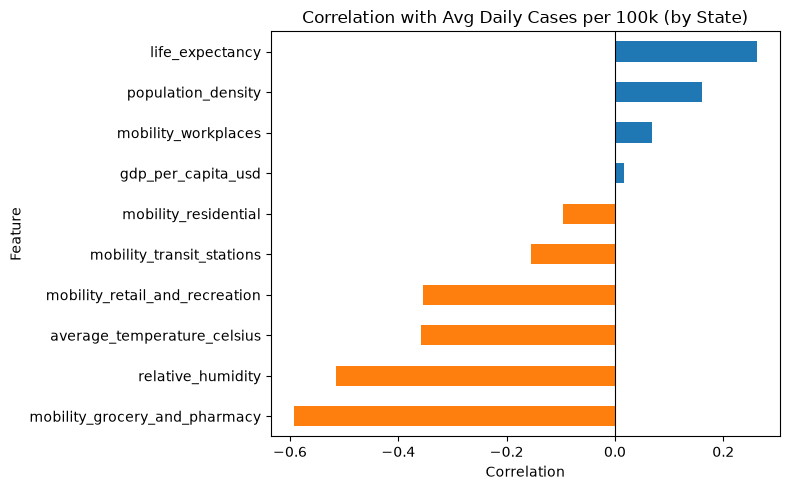

In [16]:
df_external = pd.read_csv("covid_germany/external_de_states.csv")

df_spread = df_external.groupby('state').mean(numeric_only=True)
df_spread['cases_per_day_100k'] = df_state_cases['cases_per_day_100k']

df_spread_corr = df_spread.corr()['cases_per_day_100k'].drop('cases_per_day_100k').sort_values()
print(df_spread_corr)

plt.figure(figsize=(8, 5))
colors = ['C1' if x < 0 else 'C0' for x in df_spread_corr]
df_spread_corr.plot(kind='barh', color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlation with Avg Daily Cases per 100k (by State)')
plt.xlabel('Correlation')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### Explanation

We merged the Google covid-19-open-data state files (saved locally as external_de_states.csv) with our state results and computed the correlation of each feature with average daily cases per 100k. The strongest correlations are grocery/pharmacy mobility (-0.592941), relative humidity (-0.515196), average temperature (-0.358368) and retail/recreation mobility (-0.354775), while population density (0.160117), GDP per capita (0.017294) and workplace mobility (0.068546) are close to zero. Correlation is not causation (for example, mobility dropped because of lockdowns after cases rose), and with only 16 states (one row per state) these numbers are rough and should not be over-interpreted.

## Team Contributions